In [1]:
import pandas as pd
from pandas.api.types import CategoricalDtype
import numpy as np
import json
import time
import xarray as xr
import scipy.signal as signal
import glob
import os
import xgboost as xgb
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, StratifiedKFold, permutation_test_score, GridSearchCV
from sklearn.metrics import classification_report, recall_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,make_scorer,balanced_accuracy_score, f1_score

import matplotlib.gridspec as gridspec
from matplotlib.ticker import FormatStrFormatter
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import seaborn as sns

from matplotlib.ticker import MultipleLocator


data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'
reference_dir = data_dir + '/CHCH_v6_reference/'
reference_mask_dir = reference_dir + 'processed{}/'
model_save_dir = reference_dir + 'models/'

model_mask_dir = data_dir + '/CHCH_v6_model/{}/model_processed_{}/'

output_dir = data_dir + '/CHCH_v6_model/figures/'


In [2]:
date = '20210518'

infile = reference_mask_dir.format(date[:6]) + '{}.nc'.format(date)
print('  <--- ' + infile)

ds = xr.open_dataset(infile)

backscatter = ds.backscatter.values 

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_reference/processed202105/20210518.nc


In [39]:
height = ds.level.values

In [6]:
magnitude_threshold = 2e-5
width_threshold = 1

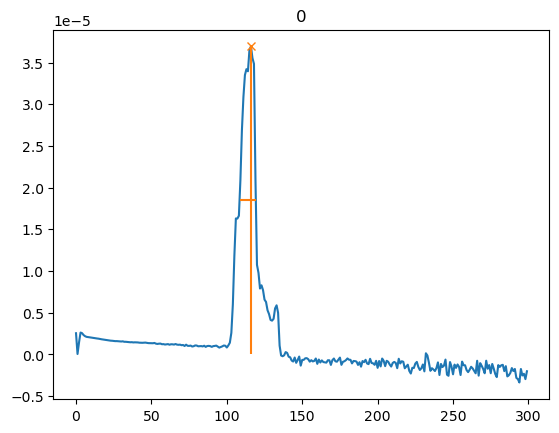

In [66]:
for t, profile in enumerate(backscatter[39:40]):
    peaks, properties = signal.find_peaks(profile,height=magnitude_threshold, width=5, rel_height=0.5, prominence=(None,None))
    if len(peaks) != 0:
        x = profile
        plt.plot(x)
        plt.plot(peaks, x[peaks], "x")
        plt.vlines(x=peaks, ymin=x[peaks] - properties["prominences"],ymax = x[peaks], color = "C1")
        plt.hlines(y=properties["width_heights"], xmin=properties["left_ips"], xmax=properties["right_ips"], color = "C1")

        plt.title(t)
        
        plt.show()


In [52]:
profile = backscatter[39]
peaks, properties = signal.find_peaks(profile,height=magnitude_threshold, width=5, rel_height=0.5, prominence=(None,None))

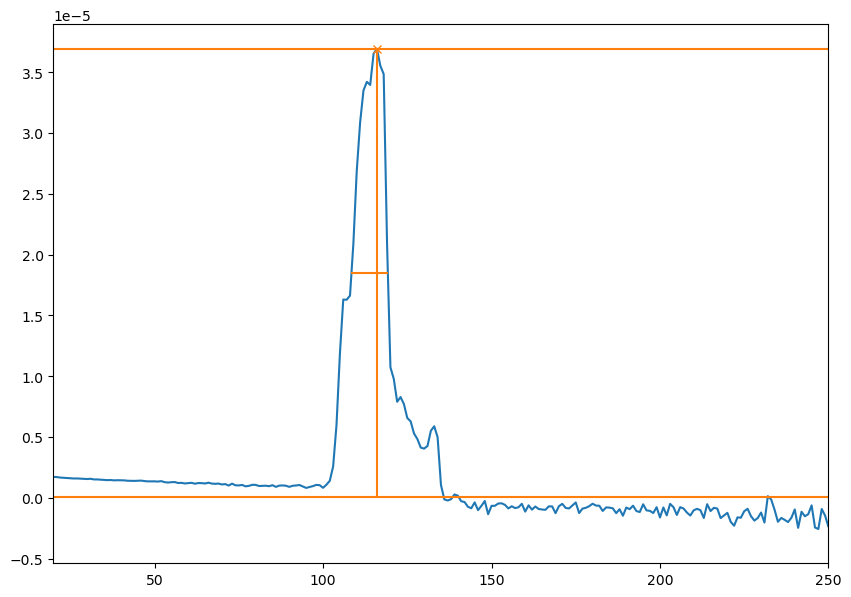

In [67]:
fig, ax = plt.subplots(1,1,figsize=(10,7))

ax.plot(profile)
ax.set_xlim((20,250))

ax.plot(peaks, x[peaks], "x")
ax.vlines(x=peaks, ymin=x[peaks] - properties["prominences"],ymax = x[peaks], color = "C1")
ax.hlines(y=properties["width_heights"], xmin=properties["left_ips"], xmax=properties["right_ips"], color = "C1")
ax.hlines(y=x[peaks] - properties["prominences"], xmin=properties["left_bases"], xmax=properties["right_bases"], color = "C1")
ax.hlines(y=x[peaks], xmin=properties["left_bases"], xmax=properties["right_bases"], color = "C1")




In [21]:
x = profile

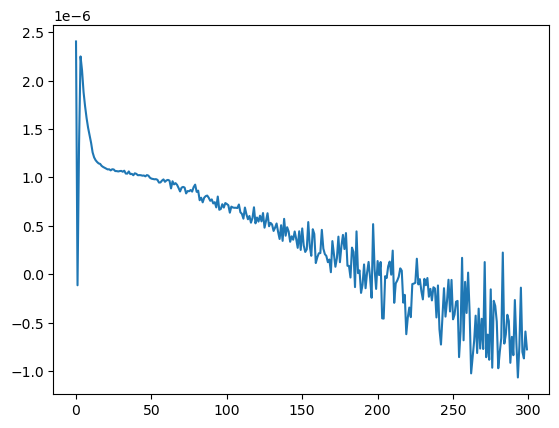

In [22]:

plt.plot(x)
plt.plot(peaks, x[peaks], "x")
plt.vlines(x=peaks, ymin=x[peaks] - properties["prominences"],ymax = x[peaks], color = "C1")
plt.hlines(y=properties["width_heights"], xmin=properties["left_ips"], xmax=properties["right_ips"], color = "C1")
plt.show()
